# SmartCheck – HelpDesk Weekly Report: RBPL vs FCPL


In [1]:
# ---- CELL 1: imports ----
import pandas as pd, numpy as np, re, os
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 50); pd.set_option('display.max_colwidth', 60)
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titlesize': 13, 'axes.titleweight': 'bold', 'font.size': 10})
BRANCH_COLORS = {'RBPL': '#1f4e79', 'FCPL': '#e08a1e'}
STATUS_COLORS = {'Open': '#c0392b', 'Closed': '#2e9c8f'}

In [2]:
# ---- CELL 2: SETTINGS 
BRANCHES = {
    'RBPL': r'C:\Users\Moses\Downloads\HelpDesk Report_20261029101229275.xlsx',
    'FCPL': r'C:\Users\Moses\Downloads\HelpDesk Report_20261029101109317.xlsx',
}
OUTPUT_ROOT = 'helpdesk_output'
AGED_DAYS = 7          # an open ticket older than this is flagged as "aged"
# Merge near-duplicate categories so the charts are not split (lower-case name -> group). Add your own as you meet them.
CATEGORY_MAP = {'ahu': 'HVAC / AC', 'hvac': 'HVAC / AC', 'air conditioning': 'HVAC / AC', 'ac': 'HVAC / AC'}
os.makedirs(OUTPUT_ROOT, exist_ok=True)

## 1. Loader & cleaner

In [3]:
# ---- CELL 3: loader + cleaner ----
DT_FMT = '%d-%m-%Y %I:%M %p'

def parse_age_hours(s):
    """'8 Days 22 Hrs 25 Mins' -> hours (float)."""
    if not isinstance(s, str): return np.nan
    m = lambda p: float(re.search(p, s).group(1)) if re.search(p, s) else 0.0
    if not re.search(r'\d', s): return np.nan
    return m(r'(\d+)\s*Day') * 24 + m(r'(\d+)\s*Hr') + m(r'(\d+)\s*Min') / 60

def fmt_hours(h):
    if pd.isna(h): return '–'
    d, hr = divmod(int(round(h)), 24)
    return f'{d}d {hr}h' if d else f'{hr}h'

def load_helpdesk(path):
    if not os.path.exists(path) or os.path.getsize(path) == 0:
        print(f'⚠ file missing or empty -> skipped ({path})'); return None
    raw = pd.read_excel(path, header=None)
    hdr = raw.index[raw.iloc[:, 0].astype(str).str.strip().eq('SNO')]
    if len(hdr) == 0: print('⚠ header row (SNO) not found -> skipped'); return None
    df = raw.iloc[hdr[0] + 1:].copy(); df.columns = raw.iloc[hdr[0]].astype(str).str.strip()
    df = df[pd.to_numeric(df['SNO'], errors='coerce').notna()].reset_index(drop=True)
    if df.empty: print('ℹ no tickets in this file'); return None
    return clean_helpdesk(df)

def clean_helpdesk(df):
    df = df.copy()
    for c in df.select_dtypes(include=['object', 'string']):
        df[c] = df[c].astype(str).str.strip().replace({'-': np.nan, 'nan': np.nan, '': np.nan, 'None': np.nan}).astype('string')
    df['Created']  = pd.to_datetime(df['Date'], format=DT_FMT, errors='coerce')
    df['Closed']   = pd.to_datetime(df['Closing Date'], format=DT_FMT, errors='coerce')
    df['SchClose'] = pd.to_datetime(df['Sch Closing Date'], format=DT_FMT, errors='coerce')
    df['Day'] = df['Created'].dt.day_name(); df['CreatedDate'] = df['Created'].dt.normalize()
    df['TicketID'] = df['Complaint ID'].str.replace(r'\s*-\s*Complaint.*$', '', regex=True)
    # Status: Completed/Closed -> 'Closed', anything else -> 'Open'. Escalation level (L2, L5...) is read from the status text.
    df['StatusRaw'] = df['Status']
    df['EscLevel'] = df['StatusRaw'].str.extract(r'\b(L\d)\b')[0].fillna('None')
    df['Status'] = np.where(df['StatusRaw'].str.contains('complet|closed|resolved', case=False, na=False), 'Closed', 'Open')
    df['AgeHours'] = df['Ticket Age'].apply(parse_age_hours)
    df['Priority'] = df['Priority'].str.title().fillna('Not set')
    df['Location'] = df['Location'].fillna('Not recorded')
    df['Category'] = df['Category'].fillna('Not recorded')
    df['CategoryGroup'] = df['Category'].apply(lambda x: CATEGORY_MAP.get(x.lower(), x))
    df['Assigned To'] = df['Assigned To'].fillna('Unassigned')
    df['ClosedBy'] = df['Closed By'].str.split(',').str[0].str.strip()          # drops the staff-number suffix
    # requester: keep the name only (drop phone/email)
    name = df['Raised By'].str.extract(r'Name\s*-\s*([^|]+)')[0].str.strip()
    df['Requester'] = name.fillna(df['Raised By'])
    df = df.drop(columns=['Raised By', 'Closed By', 'Date', 'Closing Date', 'Sch Closing Date'])
    # time to close (hours): Closing Date - Created; fall back to SmartCheck's own age for closed tickets
    df['HoursToClose'] = (df['Closed'] - df['Created']).dt.total_seconds() / 3600
    df.loc[(df['Status'] == 'Closed') & df['HoursToClose'].isna(), 'HoursToClose'] = df['AgeHours']
    df.loc[df['Status'] == 'Open', 'HoursToClose'] = np.nan
    # SLA as reported by SmartCheck (closed tickets only)
    sla = df['SLA'].str.strip().str.lower()
    df['SLA_Result'] = np.select([df['Status'].eq('Open'), sla.str.contains('outside', na=False), sla.str.contains('within|met', na=False)],
                                 ['Open', 'Outside SLA', 'Within SLA'], default='Not stated')
    df['Rating'] = pd.to_numeric(df['Rating'], errors='coerce')
    # report time = the moment the file was exported, recovered from open tickets (Created + Ticket Age)
    op = df[df['Status'] == 'Open']
    rt = (op['Created'] + pd.to_timedelta(op['AgeHours'], unit='h')).median() if len(op) else pd.NaT
    df['ReportTime'] = rt if pd.notna(rt) else df['Closed'].max()
    df['OpenAgeDays'] = np.where(df['Status'].eq('Open'), df['AgeHours'] / 24, np.nan)
    df['PastSchedule'] = df['Status'].eq('Open') & df['SchClose'].notna() & (df['ReportTime'] > df['SchClose'])
    return df


## 2. Analysis for one branch (runs automatically for each branch below)


In [4]:
def analyse(BRANCH):
    """Full helpdesk analysis for one branch. Returns a dict of results (or None if no data)."""
    OUT = f'{OUTPUT_ROOT}/{BRANCH}'; os.makedirs(OUT, exist_ok=True)
    print('=' * 70); print(f'  {BRANCH}'); print('=' * 70)
    T = load_helpdesk(BRANCHES[BRANCH])
    if T is None: print(f'⚠ {BRANCH}: no data loaded – check the path in Cell 2'); return None
    n = len(T); closed = T[T.Status == 'Closed']; opn = T[T.Status == 'Open']
    rt = T['ReportTime'].iloc[0]
    print(f'{n} tickets raised {T.Created.min():%a %d-%b} to {T.Created.max():%a %d-%b %Y}; file exported about {rt:%a %d-%b %H:%M}.')
    wk = T.Created.min().normalize() - pd.Timedelta(days=T.Created.min().weekday())
    quiet = [d.strftime('%a %d-%b') for d in pd.date_range(wk, periods=5) if d not in set(T.CreatedDate)]
    if quiet: print('ℹ No tickets raised on:', ', '.join(quiet), '(if unexpected, check the export date range)')

    # ---------- headline numbers ----------
    cl_sla = closed[closed.SLA_Result.isin(['Within SLA', 'Outside SLA'])]
    K = {
        'Tickets raised': n, 'Closed': len(closed), 'Still open': len(opn),
        'Closure rate': f'{len(closed)/n:.0%}',
        'Avg time to close': fmt_hours(closed.HoursToClose.mean()),
        'Median time to close': fmt_hours(closed.HoursToClose.median()),
        'Closed within SLA': f"{(cl_sla.SLA_Result == 'Within SLA').mean():.0%}" if len(cl_sla) else '–',
        'Closed outside SLA': int((closed.SLA_Result == 'Outside SLA').sum()),
        f'Open longer than {AGED_DAYS} days': int((opn.OpenAgeDays > AGED_DAYS).sum()),
        'Oldest open ticket': fmt_hours(opn.AgeHours.max()),
        'Open and past scheduled closing': int(opn.PastSchedule.sum()),
        'Open at escalation level L5': int((opn.EscLevel == 'L5').sum()),
        'High-priority tickets': int((T.Priority == 'High').sum()),
        'Average rating (closed)': round(closed.Rating.mean(), 1) if closed.Rating.notna().any() else '–',
    }
    print('\n--- 1. Headline numbers ---'); display(pd.Series(K, name=BRANCH).to_frame())

    # ---------- daily trend ----------
    print('\n--- 2. Tickets raised per day ---')
    days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
    daily = T.pivot_table(index='Day', columns='Status', values='SNO', aggfunc='count', fill_value=0).reindex(days).fillna(0).astype(int)
    for s in ['Open', 'Closed']:
        if s not in daily: daily[s] = 0
    daily = daily[['Open', 'Closed']]; daily['Total'] = daily.sum(axis=1); display(daily)
    ax = daily[['Open', 'Closed']].plot(kind='bar', stacked=True, color=[STATUS_COLORS['Open'], STATUS_COLORS['Closed']], rot=0, ax=plt.subplots()[1])
    for i, t in enumerate(daily.Total): ax.text(i, t + .05, str(t), ha='center', fontweight='bold')
    ax.set_title(f'{BRANCH}: Tickets raised per day (status today)'); ax.set_xlabel(''); ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    plt.tight_layout(); plt.savefig(f'{OUT}/01_daily_tickets.png', dpi=150); plt.show()

    # ---------- category / location / priority ----------
    def hbar(series, title, fname, color):
        s = series.sort_values(); ax = s.plot(kind='barh', color=color, ax=plt.subplots()[1]); ax.set_title(title); ax.set_ylabel('')
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        for i, v in enumerate(s): ax.text(v + .02, i, str(int(v)), va='center')
        plt.tight_layout(); plt.savefig(f'{OUT}/{fname}', dpi=150); plt.show()
    print('\n--- 3. What is being reported, and where ---')
    cat = T.groupby('CategoryGroup').agg(Tickets=('SNO', 'count'), Open=('Status', lambda s: (s == 'Open').sum()),
                                         AvgHoursToClose=('HoursToClose', 'mean')).sort_values('Tickets', ascending=False).round(1)
    display(cat); hbar(cat.Tickets, f'{BRANCH}: Tickets by category', '02_category.png', '#1f4e79')
    loc = T.groupby('Location').agg(Tickets=('SNO', 'count'), Open=('Status', lambda s: (s == 'Open').sum())).sort_values('Tickets', ascending=False)
    display(loc); hbar(loc.Tickets, f'{BRANCH}: Tickets by floor / location', '03_location.png', '#2e9c8f')
    pri = T.groupby(['Priority', 'Status']).size().unstack(fill_value=0)
    for s in ['Open', 'Closed']:
        if s not in pri: pri[s] = 0
    pri = pri.reindex([p for p in ['High', 'Medium', 'Low', 'Not set'] if p in pri.index])[['Open', 'Closed']]; display(pri)
    esc = T.groupby('EscLevel').size().rename('Tickets').to_frame(); display(esc)

    # ---------- resolution performance ----------
    print('\n--- 4. Resolution performance (closed tickets) ---')
    if len(closed):
        perf = closed[['Complaint', 'CategoryGroup', 'Location', 'Priority', 'ClosedBy', 'HoursToClose', 'SLA_Result', 'Rating']].copy()
        perf['HoursToClose'] = perf.HoursToClose.round(1); display(perf.sort_values('HoursToClose', ascending=False))
    else: print('No tickets were closed.')

    # ---------- open tickets ----------
    print('\n--- 5. Open tickets, oldest first (needs follow-up) ---')
    open_list = opn.sort_values('AgeHours', ascending=False)[['TicketID', 'Created', 'Location', 'CategoryGroup', 'Complaint', 'Priority', 'Assigned To', 'EscLevel', 'OpenAgeDays']].copy()
    open_list['OpenAgeDays'] = open_list.OpenAgeDays.round(1); display(open_list)
    if len(opn):
        a = opn.sort_values('AgeHours'); ax = a.set_index(a['Complaint'].str[:32] + ' (' + a['Location'] + ')')['OpenAgeDays'].plot(kind='barh', color=STATUS_COLORS['Open'], ax=plt.subplots()[1])
        ax.axvline(AGED_DAYS, ls='--', color='grey'); ax.text(AGED_DAYS + 0.05, len(a) - 0.45, f'{AGED_DAYS}-day mark', color='grey', va='bottom'); ax.set_xlabel('Days open')
        ax.set_title(f'{BRANCH}: Age of open tickets (days)'); ax.set_ylabel(''); plt.tight_layout(); plt.savefig(f'{OUT}/04_open_ticket_age.png', dpi=150); plt.show()

    # ---------- workload ----------
    print('\n--- 6. Workload by assignee ---')
    work = T.groupby(['Assigned To', 'Status']).size().unstack(fill_value=0)
    for s in ['Open', 'Closed']:
        if s not in work: work[s] = 0
    work = work[['Open', 'Closed']]; work['Total'] = work.sum(axis=1); work['Closure rate'] = (work.Closed / work.Total).map('{:.0%}'.format)
    work = work.sort_values('Total', ascending=False); display(work)
    w = work[['Open', 'Closed']].iloc[::-1]
    ax = w.plot(kind='barh', stacked=True, color=[STATUS_COLORS['Open'], STATUS_COLORS['Closed']], ax=plt.subplots()[1]); ax.set_title(f'{BRANCH}: Tickets per assignee'); ax.set_ylabel('')
    ax.xaxis.set_major_locator(MaxNLocator(integer=True)); plt.tight_layout(); plt.savefig(f'{OUT}/05_workload.png', dpi=150); plt.show()

    # ---------- repeats & data quality ----------
    print('\n--- 7. Repeat issues & data quality ---')
    rep = T.groupby(['Location', 'CategoryGroup']).agg(Tickets=('SNO', 'count'), Examples=('Complaint', lambda s: ' | '.join(s.unique()[:3]))).query('Tickets > 1').sort_values('Tickets', ascending=False)
    print('Same floor + category raised more than once (possible recurring fault):'); display(rep)
    req = T.groupby('Requester').size().sort_values(ascending=False).rename('Tickets').to_frame(); print('Who raises the tickets:'); display(req)
    dq = pd.Series({'Priority not set': int((T.Priority == 'Not set').sum()), 'Category not recorded': int((T.Category == 'Not recorded').sum()),
                    'Unassigned': int((T['Assigned To'] == 'Unassigned').sum()), 'Closed without rating': int(closed.Rating.isna().sum()),
                    'Closed with SLA not stated': int((closed.SLA_Result == 'Not stated').sum())}).to_frame('Tickets'); dq['% of tickets'] = (dq.Tickets / n * 100).round(0); display(dq)

    # ---------- talking points ----------
    print('\n--- 8. Talking points ---')
    top_cat, top_loc = cat.index[0], loc.index[0]
    pts = [f'{BRANCH} raised {n} helpdesk ticket(s) this week: {len(closed)} closed ({len(closed)/n:.0%}) and {len(opn)} still open.',
           f'Most tickets were about {top_cat} ({cat.Tickets.iloc[0]}); the busiest location was {top_loc} ({loc.Tickets.iloc[0]}).']
    if len(closed): pts.append(f'Closed tickets took {fmt_hours(closed.HoursToClose.mean())} on average; {K["Closed outside SLA"]} of {len(closed)} closed outside SLA.')
    if len(opn): pts.append(f'{int((opn.OpenAgeDays > AGED_DAYS).sum())} open ticket(s) are older than {AGED_DAYS} days; the oldest has been open {fmt_hours(opn.AgeHours.max())}. {int(opn.PastSchedule.sum())} are past their scheduled closing time.')
    if len(rep): pts.append(f'Recurring faults: {len(rep)} floor/category combination(s) were reported more than once (e.g. {rep.index[0][0]} – {rep.index[0][1]}).')
    if dq.loc['Priority not set', 'Tickets'] or dq.loc['Closed without rating', 'Tickets']:
        pts.append(f'{int(dq.loc["Priority not set", "Tickets"])} ticket(s) have no priority set and {int(dq.loc["Closed without rating", "Tickets"])} closed ticket(s) have no rating.')
    for p in pts: print('•', p)

    # ---------- export ----------
    with pd.ExcelWriter(f'{OUT}/HelpDesk_{BRANCH}_weekly_summary.xlsx') as w_:
        pd.Series(K, name=BRANCH).to_frame().to_excel(w_, sheet_name='KPIs'); daily.to_excel(w_, sheet_name='Daily'); cat.to_excel(w_, sheet_name='Category')
        loc.to_excel(w_, sheet_name='Location'); pri.to_excel(w_, sheet_name='Priority'); open_list.to_excel(w_, sheet_name='Open tickets', index=False)
        work.to_excel(w_, sheet_name='Workload'); rep.to_excel(w_, sheet_name='Repeat issues'); dq.to_excel(w_, sheet_name='Data quality')
        T.drop(columns=['ReportTime']).to_excel(w_, sheet_name='Clean data', index=False)
    print(f'\nSaved to {os.path.abspath(OUT)}')
    return dict(BRANCH=BRANCH, T=T, K=K, daily=daily, cat=cat, loc=loc, pri=pri, work=work, open_list=open_list, rep=rep, dq=dq, pts=pts)

## 3. Run RBPL and FCPL

  RBPL
2 tickets raised Mon 19-Oct to Tue 20-Oct 2026; file exported about Thu 29-Oct 09:12.
ℹ No tickets raised on: Wed 21-Oct, Thu 22-Oct, Fri 23-Oct (if unexpected, check the export date range)

--- 1. Headline numbers ---


,RBPL
Tickets raised,2
Closed,0
Still open,2
Closure rate,0%
Avg time to close,–
Median time to close,–
Closed within SLA,–
Closed outside SLA,0
Open longer than 7 days,2
Oldest open ticket,10d 2h



--- 2. Tickets raised per day ---


Status,Open,Closed,Total
Day,,,
Monday,1,0,1
Tuesday,1,0,1
Wednesday,0,0,0
Thursday,0,0,0
Friday,0,0,0


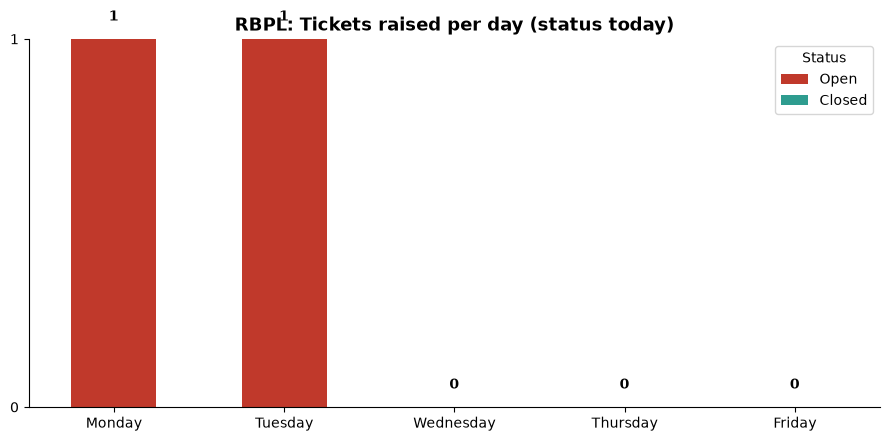


--- 3. What is being reported, and where ---


,Tickets,Open,AvgHoursToClose
CategoryGroup,,,
HVAC / AC,1,1,NaN
Plumbing,1,1,NaN


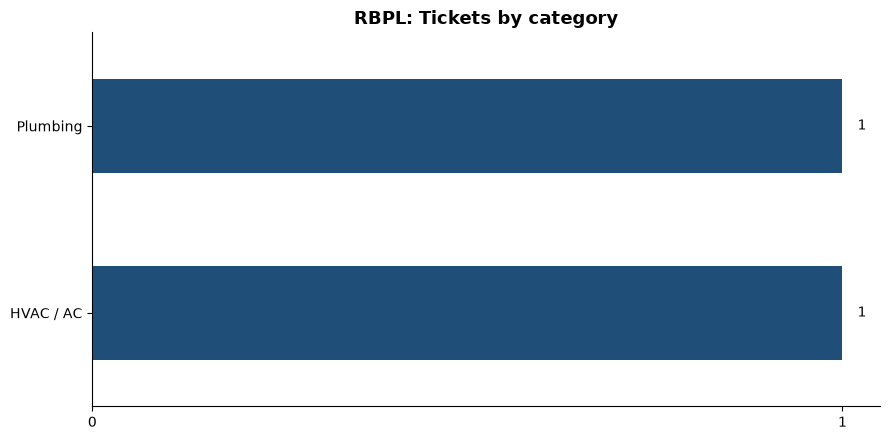

,Tickets,Open
Location,,
9th floor,2,2


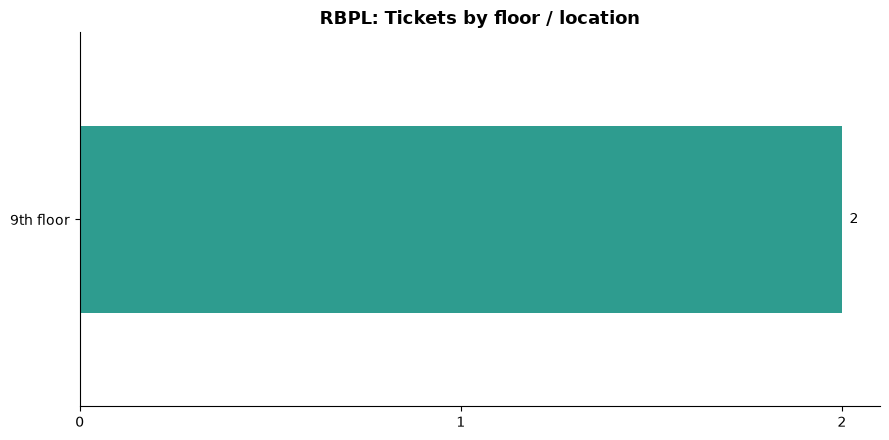

Status,Open,Closed
Priority,,
Low,2,0


,Tickets
EscLevel,
L5,2



--- 4. Resolution performance (closed tickets) ---
No tickets were closed.

--- 5. Open tickets, oldest first (needs follow-up) ---


2,TicketID,Created,Location,CategoryGroup,Complaint,Priority,Assigned To,EscLevel,OpenAgeDays
0,CT26101906898,2026-10-19 07:28:00,9th floor,HVAC / AC,CHILLER ISSUE,Low,Olufunsho Olusegun,L5,10.1
1,CT26102040939,2026-10-20 08:43:00,9th floor,Plumbing,Repair or replacement of the hand wash in the pantry,Low,Daniel Uwa,L5,9.0


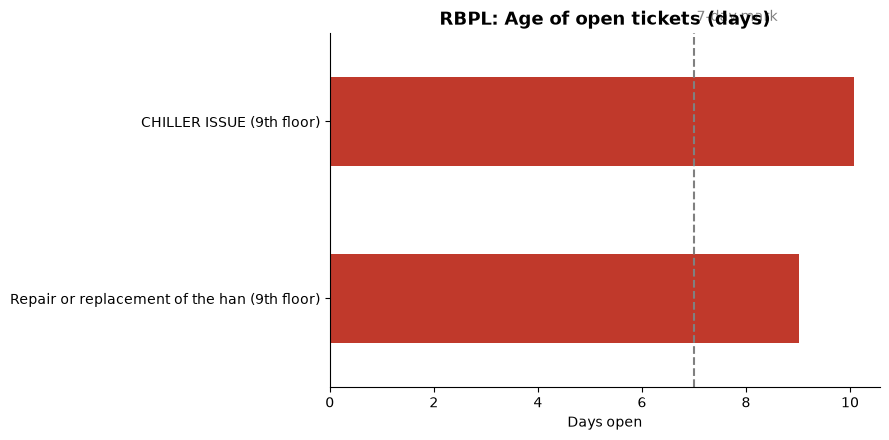


--- 6. Workload by assignee ---


Status,Open,Closed,Total,Closure rate
Assigned To,,,,
Daniel Uwa,1,0,1,0%
Olufunsho Olusegun,1,0,1,0%


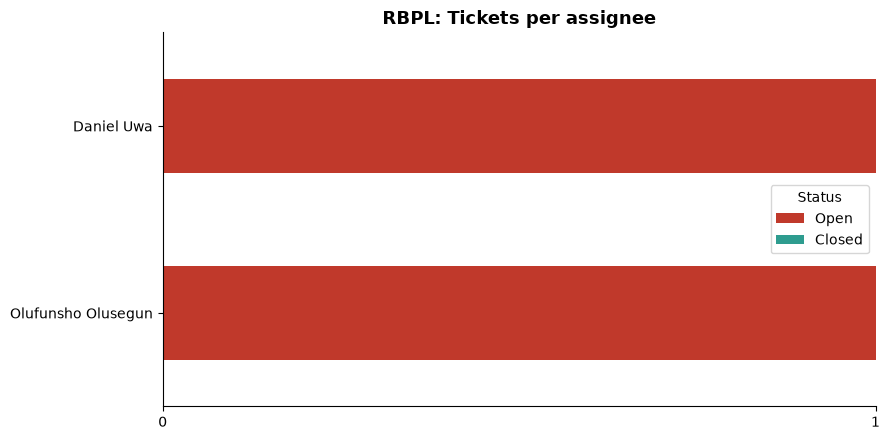


--- 7. Repeat issues & data quality ---
Same floor + category raised more than once (possible recurring fault):


,,Tickets,Examples
Location,CategoryGroup,,


Who raises the tickets:


,Tickets
Requester,
Ehijele Ivbarialu,1
Giesecke+Devrient,1


,Tickets,% of tickets
Priority not set,0,0.0
Category not recorded,0,0.0
Unassigned,0,0.0
Closed without rating,0,0.0
Closed with SLA not stated,0,0.0



--- 8. Talking points ---
• RBPL raised 2 helpdesk ticket(s) this week: 0 closed (0%) and 2 still open.
• Most tickets were about HVAC / AC (1); the busiest location was 9th floor (2).
• 2 open ticket(s) are older than 7 days; the oldest has been open 10d 2h. 2 are past their scheduled closing time.

Saved to C:\Users\Moses\Downloads\helpdesk_output\RBPL
  FCPL
11 tickets raised Mon 19-Oct to Tue 20-Oct 2026; file exported about Thu 29-Oct 09:10.
ℹ No tickets raised on: Wed 21-Oct, Thu 22-Oct, Fri 23-Oct (if unexpected, check the export date range)

--- 1. Headline numbers ---


,FCPL
Tickets raised,11
Closed,4
Still open,7
Closure rate,36%
Avg time to close,1d 4h
Median time to close,1d 4h
Closed within SLA,0%
Closed outside SLA,4
Open longer than 7 days,7
Oldest open ticket,9d 22h



--- 2. Tickets raised per day ---


Status,Open,Closed,Total
Day,,,
Monday,4,2,6
Tuesday,3,2,5
Wednesday,0,0,0
Thursday,0,0,0
Friday,0,0,0


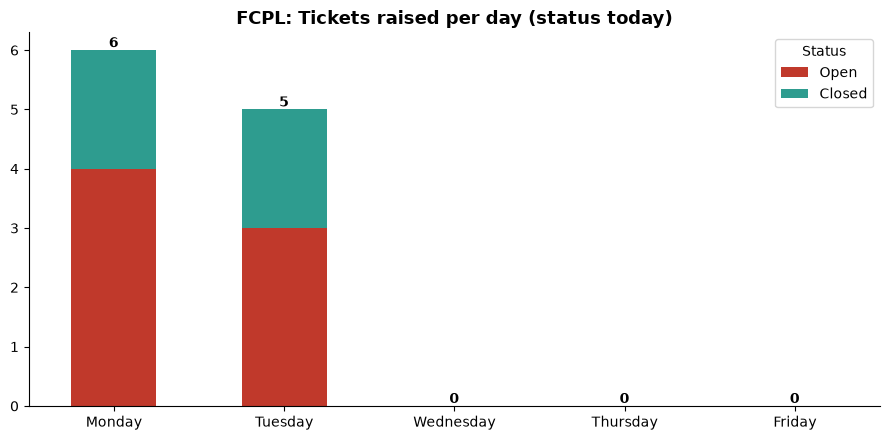


--- 3. What is being reported, and where ---


,Tickets,Open,AvgHoursToClose
CategoryGroup,,,
HVAC / AC,4,2,18.6
Civil,3,3,NaN
Carpentry,2,0,37.7
Common Areas,1,1,NaN
Plumbing,1,1,NaN


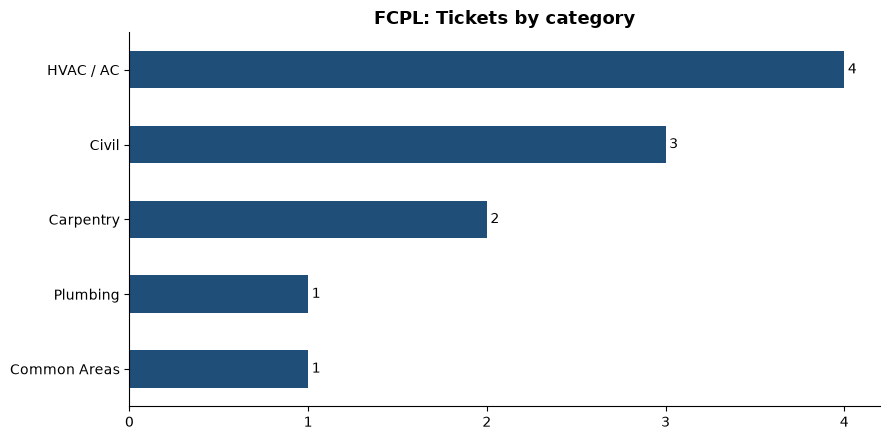

,Tickets,Open
Location,,
9th floor,3,2
7th floor,3,1
Penthouse,2,2
3rd floor,1,1
5th floor,1,0
6th floor,1,1


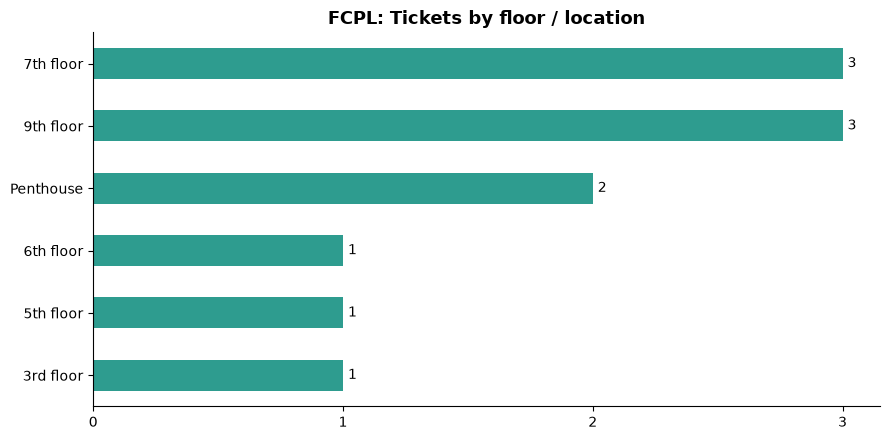

Status,Open,Closed
Priority,,
High,1,0
Medium,2,2
Low,3,0
Not set,1,2


,Tickets
EscLevel,
L2,2
L5,6
None,3



--- 4. Resolution performance (closed tickets) ---


2,Complaint,CategoryGroup,Location,Priority,ClosedBy,HoursToClose,SLA_Result,Rating
9,Rear exit door bad,Carpentry,7th floor,Medium,Alabi Michael Olusegun,37.8,Outside SLA,5
10,key and handle is bad,Carpentry,7th floor,Medium,Alabi Michael Olusegun,37.7,Outside SLA,4
2,AC not cooling,HVAC / AC,9th floor,Not set,Alabi Michael Olusegun,18.9,Outside SLA,4
4,AC servicing,HVAC / AC,5th floor,Not set,Alabi Michael Olusegun,18.3,Outside SLA,4



--- 5. Open tickets, oldest first (needs follow-up) ---


2,TicketID,Created,Location,CategoryGroup,Complaint,Priority,Assigned To,EscLevel,OpenAgeDays
0,CT26101913088,2026-10-19 11:37:00,Penthouse,Civil,Open POP ceiling,Medium,Anthony Ogbonna Nwosu,L5,9.9
1,CT26101946459,2026-10-19 11:39:00,9th floor,Civil,Open POP ceiling,Medium,Anthony Ogbonna Nwosu,L5,9.9
3,CT261019800411,2026-10-19 12:23:00,6th floor,Plumbing,Faulty extractor fans - Odour issues,Low,Anthony Ogbonna Nwosu,L5,9.9
5,CT261019135913,2026-10-19 12:29:00,3rd floor,HVAC / AC,AC not cooling,Low,Ogunbiyi Babajide Titus,L5,9.9
6,CT261020061714,2026-10-20 09:52:00,Penthouse,HVAC / AC,Board room AC not working,Not set,Ogunbiyi Babajide Titus,L5,9.0
7,CT261020236115,2026-10-20 16:27:00,9th floor,Civil,Broken kitchen sink marble,High,Bakare Wasiu,L5,8.7
8,CT261020791116,2026-10-20 16:34:00,7th floor,Common Areas,Interlock bricks at the lift lobby,Low,Anthony Ogbonna Nwosu,None,8.7


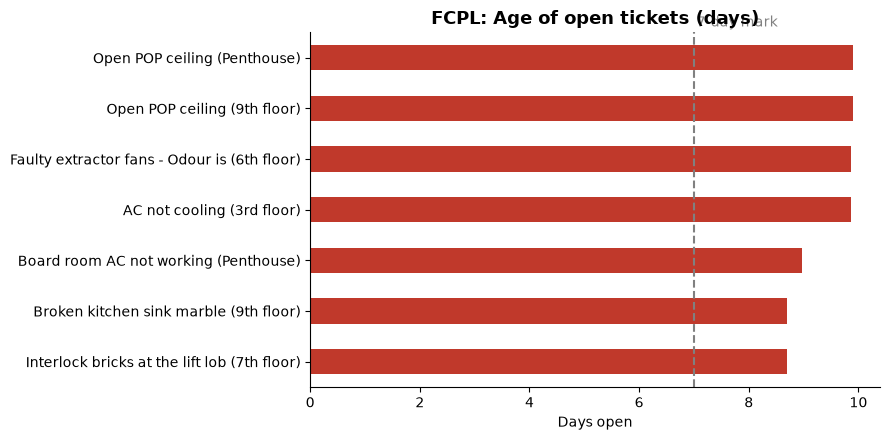


--- 6. Workload by assignee ---


Status,Open,Closed,Total,Closure rate
Assigned To,,,,
Anthony Ogbonna Nwosu,4,2,6,33%
Alabi Michael Olusegun,0,2,2,100%
Ogunbiyi Babajide Titus,2,0,2,0%
Bakare Wasiu,1,0,1,0%


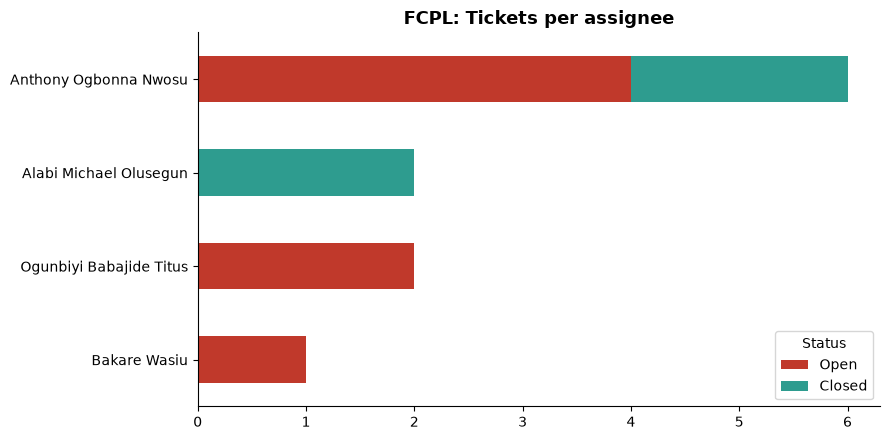


--- 7. Repeat issues & data quality ---
Same floor + category raised more than once (possible recurring fault):


,,Tickets,Examples
Location,CategoryGroup,,
7th floor,Carpentry,2,Rear exit door bad | key and handle is bad
9th floor,Civil,2,Open POP ceiling | Broken kitchen sink marble


Who raises the tickets:


,Tickets
Requester,
Faith Ometere Gadimoh,8
Ehijele Ivbarialu,2
Gideon Adesawe,1


,Tickets,% of tickets
Priority not set,3,27.0
Category not recorded,0,0.0
Unassigned,0,0.0
Closed without rating,0,0.0
Closed with SLA not stated,0,0.0



--- 8. Talking points ---
• FCPL raised 11 helpdesk ticket(s) this week: 4 closed (36%) and 7 still open.
• Most tickets were about HVAC / AC (4); the busiest location was 9th floor (3).
• Closed tickets took 1d 4h on average; 4 of 4 closed outside SLA.
• 7 open ticket(s) are older than 7 days; the oldest has been open 9d 22h. 7 are past their scheduled closing time.
• Recurring faults: 2 floor/category combination(s) were reported more than once (e.g. 7th floor – Carpentry).
• 3 ticket(s) have no priority set and 0 closed ticket(s) have no rating.

Saved to C:\Users\Moses\Downloads\helpdesk_output\FCPL

Branches completed: ['RBPL', 'FCPL']


In [5]:
results = {}
for b in BRANCHES:
    r = analyse(b)
    if r is not None: results[b] = r
print('\nBranches completed:', list(results))

## 4. Side-by-side comparison (for the COO)

In [6]:
# ---- comparison table ----
assert results, 'No branch loaded any data – check the file paths in Cell 2.'
comparison = pd.DataFrame({b: r['K'] for b, r in results.items()})
extra = {}
for b, r in results.items():
    T = r['T']
    extra[b] = {'Top category': f"{r['cat'].index[0]} ({r['cat'].Tickets.iloc[0]})", 'Busiest location': f"{r['loc'].index[0]} ({r['loc'].Tickets.iloc[0]})",
                'Tickets with no priority set': int((T.Priority == 'Not set').sum()), 'Recurring floor/category issues': len(r['rep'])}
comparison = pd.concat([comparison, pd.DataFrame(extra)]); display(comparison)

,RBPL,FCPL
Tickets raised,2,11
Closed,0,4
Still open,2,7
Closure rate,0%,36%
Avg time to close,–,1d 4h
Median time to close,–,1d 4h
Closed within SLA,–,0%
Closed outside SLA,0,4
Open longer than 7 days,2,7
Oldest open ticket,10d 2h,9d 22h


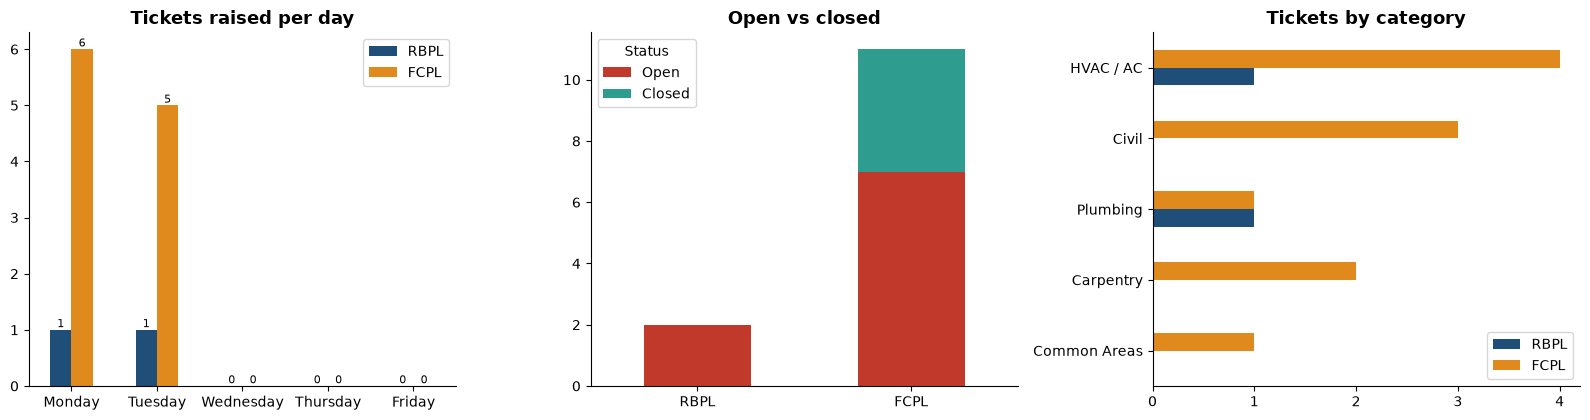

In [7]:
# ---- comparison charts ----
days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
dd = pd.DataFrame({b: r['daily']['Total'] for b, r in results.items()}).reindex(days).fillna(0)
dd.plot(kind='bar', ax=ax[0], rot=0, color=[BRANCH_COLORS[c] for c in dd.columns]); ax[0].set_title('Tickets raised per day'); ax[0].set_xlabel('')
for c in ax[0].containers: ax[0].bar_label(c, fontsize=8)
st = pd.DataFrame({b: r['T'].Status.value_counts() for b, r in results.items()}).T.fillna(0).reindex(columns=['Open', 'Closed']).fillna(0)
st.plot(kind='bar', stacked=True, ax=ax[1], rot=0, color=[STATUS_COLORS['Open'], STATUS_COLORS['Closed']]); ax[1].set_title('Open vs closed')
cg = pd.DataFrame({b: r['cat'].Tickets for b, r in results.items()}).fillna(0)
cg = cg.loc[cg.sum(axis=1).sort_values().index]
cg.plot(kind='barh', ax=ax[2], color=[BRANCH_COLORS[c] for c in cg.columns]); ax[2].set_title('Tickets by category'); ax[2].set_ylabel('')
for a in ax: a.yaxis.set_major_locator(MaxNLocator(integer=True)) if a is not ax[2] else a.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout(); plt.savefig(f'{OUTPUT_ROOT}/Comparison_charts.png', dpi=150); plt.show()

In [8]:
# ---- comparison talking points + save ----
for b, r in results.items(): print(f'• {b}: {r["K"]["Tickets raised"]} raised, {r["K"]["Closed"]} closed, {r["K"]["Still open"]} open; closure rate {r["K"]["Closure rate"]}.')
if len(results) == 2:
    (a, ra), (b, rb) = results.items()
    if ra['K']['Tickets raised'] != rb['K']['Tickets raised']:
        hi = a if ra['K']['Tickets raised'] > rb['K']['Tickets raised'] else b
        print(f'• {hi} raised more tickets this week.')
with pd.ExcelWriter(f'{OUTPUT_ROOT}/HelpDesk_comparison.xlsx') as w:
    comparison.to_excel(w, sheet_name='Comparison')
    for b, r in results.items(): r['open_list'].to_excel(w, sheet_name=f'{b} open tickets', index=False)
print('Saved to:', os.path.abspath(OUTPUT_ROOT))

• RBPL: 2 raised, 0 closed, 2 open; closure rate 0%.
• FCPL: 11 raised, 4 closed, 7 open; closure rate 36%.
• FCPL raised more tickets this week.
Saved to: C:\Users\Moses\Downloads\helpdesk_output
